# The published predictors on their own hold-out tables, reproduced and scored on two statistics

**Level 3: State of the art** · Needs: 02-classical-prediction/01-the-classical-equation-on-one-blast, 02-classical-prediction/02-the-rock-factor · Reading time: about 25 minutes

## Objectives

The state of the art for this problem is two published papers that each validate three predictors on a small hold-out set and print their predictions in a table. This notebook takes those printed columns as the reference, scores them with the engine's metrics, recomputes the same predictors from their published equations, and compares the two with the classical arm built in the previous notebooks.

By the end you will have:

- scored the printed classical, regression and network columns on the 12-blast hold-out with two named statistics, and seen they are not the same number;
- recomputed the published regression from its equations on both hold-outs and compared it with the table the papers printed;
- measured how much one blast that is also in the training table changes the picture, and confirmed every number against the committed benchmark.

## Setup

Install the packages with the exact pins of `notebooks/requirements.txt`. The engine is `blastfrag`, published on PyPI; the other packages are its numerical base and the plotting library.

```bash
pip install blastfrag==0.4.0 numpy==2.5.4 matplotlib==3.11.2
```

This cell imports nothing from the notebook yet: it reads the installed versions from the package metadata and prints them, so the output records exactly which engine produced every number below.

In [1]:
# Print the installed version of every package this notebook uses
from importlib.metadata import version

for name in ("blastfrag", "numpy", "matplotlib",):
    print(f"{name}=={version(name)}")

blastfrag==0.4.0
numpy==2.5.4
matplotlib==3.11.2


## Data

| Source | Owner and URL | Licence class | File the notebook reads |
|---|---|---|---|
| The 13-blast hold-out and the printed predictions of the 2010 paper | Hudaverdi, Kulatilake and Kuzu 2010, https://doi.org/10.1002/nag.957 | numeric facts reused with citation; the article never ships | `bf.load_holdout(protocol="2010")` inside the `blastfrag` wheel |
| The 12-blast hold-out and the printed predictions of the 2012 paper (Kuz-Ram, regression, network) | Kulatilake, Hudaverdi and Wu 2012, https://doi.org/10.1007/s10706-012-9496-3 | numeric facts reused with citation; the article never ships | `bf.load_holdout(protocol="2012")` |
| The committed reproduction the bake computed | this repository (MIT) | the product's own licence | `data/derived/benchmark.json`, field `published_reproduction` |

Each hold-out blast carries, in its metadata, the value each paper printed for it, so the printed column is data the notebook scores like any other prediction.

## Method

Scoring a prediction column needs two statistics, because this literature uses one name for two quantities:

- the **Pearson r2**, the square of the correlation between predicted and measured, which a straight line of any slope and offset can satisfy;
- the **variance explained about the identity line**, `1 - SS_res / SS_tot` with the residuals taken against `predicted = measured`, which penalises bias and wrong slope.

The engine's `bf.score` returns both under their own names (`pearson_r2`, `r2_identity`), and every figure of the product carries the name of its statistic. The cells below build a `Prediction` for each printed value so the printed table goes through exactly the same scorer as the engine's own arms.

### Step 1: the printed columns on the 12-blast hold-out

The cell scores the printed Kuz-Ram, regression and network columns, plus the null model (the training mean, which uses no input at all), and prints both statistics for each.

In [2]:
# Imports, the 12-blast hold-out and a helper that turns a printed column into predictions
import json
from pathlib import Path

import blastfrag as bf
import matplotlib.pyplot as plt
import numpy as np

DERIVED = Path("../../../data/derived")
holdout = bf.load_holdout(protocol="2012")
train = bf.load_training_corpus()

printed = lambda rows, column: [bf.Prediction(method=column, blast_id=b.blast_id, x50_m=b.meta["published"][column]) for b in rows]

columns = {"Kuz-Ram (kuzram_2012)": "kuzram_2012", "regression (regression_2012)": "regression_2012", "network (nn_mean_2012)": "nn_mean_2012"}
print(f"{'printed column':<32}{'Pearson r2':>12}{'r2 identity':>14}{'RMSE (m)':>10}")
scores = {}
for label, column in columns.items():
    s = bf.score(holdout, printed(holdout, column), method=column)
    scores[column] = s
    print(f"{label:<32}{s.pearson_r2:>12.4f}{s.r2_identity:>14.4f}{s.rmse_m:>10.4f}")
null = bf.null_model_score(holdout, training_mean_m=bf.training_mean(train))
print(f"{'null (training mean)':<32}{'-':>12}{null.r2_identity:>14.4f}{null.rmse_m:>10.4f}")

printed column                    Pearson r2   r2 identity  RMSE (m)
Kuz-Ram (kuzram_2012)                 0.5698        0.2318    0.1279
regression (regression_2012)          0.8197        0.7082    0.0788
network (nn_mean_2012)                0.9372        0.9096    0.0439
null (training mean)                       -       -0.0093    0.1466


### Step 2: recompute the published regression from its equations

The regression of the 2010 paper is two power laws, one per rock-stiffness group, with a discriminant that routes each blast. The engine's `PublishedRegression` applies the equations as printed. The cell scores its output against the table the papers printed for the same blasts, on both hold-outs, and then checks the result against the numbers the bake committed.

In [3]:
# Printed against recomputed regression on each hold-out, and the committed values
benchmark = json.loads((DERIVED / "benchmark.json").read_text(encoding="utf-8"))
committed = benchmark["published_reproduction"]
arm = bf.PublishedRegression()
union = bf.load_holdout(protocol="union")
print(f"{'hold-out':<10}{'n':>3}{'printed':>10}{'recomputed':>14}{'gain':>9}  equals the committed values")
for label, column in (("2010", "regression_2010"), ("2012", "regression_2012")):
    rows = [b for b in union if b.meta["published"][column] is not None]
    as_printed = bf.score(rows, printed(rows, column))
    recomputed = bf.score(rows, arm.predict(rows))
    same = abs(as_printed.r2_identity - committed[label]["as_published"]["r2_identity"]) < 1e-9 and abs(recomputed.r2_identity - committed[label]["recomputed"]["r2_identity"]) < 1e-9
    print(f"{label:<10}{len(rows):>3}{as_printed.r2_identity:>10.4f}{recomputed.r2_identity:>14.4f}{recomputed.r2_identity - as_printed.r2_identity:>9.4f}  {same}")

hold-out    n   printed    recomputed     gain  equals the committed values
2010       13    0.7467        0.8537   0.1070  True
2012       12    0.7082        0.8272   0.1190  True


### Step 3: the classical column against the arm of the previous notebooks

The printed Kuz-Ram column and the engine's `Kuznetsov` arm (which uses the per-site rock factor recovered from that same column) should nearly coincide; the difference is the rounding of the printed values to two decimals. The cell lists the two side by side for the 12 blasts and prints the largest gap.

In [4]:
# Printed Kuz-Ram column beside the engine's classical arm, blast by blast
classical = bf.Kuznetsov().predict(holdout)
print(f"{'blast':<7}{'measured':>10}{'printed':>10}{'engine':>9}")
gaps = []
for blast, prediction in zip(holdout, classical):
    column = blast.meta["published"]["kuzram_2012"]
    value = prediction.x50_m
    if value is not None:
        gaps.append(abs(value - column))
    print(f"{blast.blast_id:<7}{blast.x50_m:>10.2f}{column:>10.2f}" + (f"{value:>9.3f}" if value is not None else f"{'-':>9}"))
print(f"largest gap between the printed column and the engine = {max(gaps):.3f} m")

blast    measured   printed   engine
En13         0.47      0.44    0.440
Ru7          0.64      0.65    0.650
Mg8          0.44      0.39    0.387
Mg9          0.25      0.30    0.302
Rc1          0.46      0.72    0.720
Mr12         0.20      0.24    0.240
Db10         0.35      0.08    0.080
Sm8          0.18      0.35    0.350
Oz8          0.23      0.20    0.198
Oz9          0.17      0.23    0.232
Ad23         0.21      0.11    0.108
Ad24         0.20      0.13    0.132
largest gap between the printed column and the engine = 0.003 m


### Step 4: the blast that is also in the training table

One blast of the 12 is also a row of the training table, which a fixed hold-out is supposed to keep apart. The cell removes it and scores the three printed columns on the remaining 11.

In [5]:
# Score the printed columns with and without the blast flagged as being in the training table
leaked = [b.blast_id for b in holdout if b.meta["in_training_table"]]
clean = [b for b in holdout if not b.meta["in_training_table"]]
print("blast in both sets:", leaked)
print(f"{'printed column':<20}{'n=12':>10}{'n=11':>10}   r2 identity")
for column in columns.values():
    full = bf.score(holdout, printed(holdout, column)).r2_identity
    without = bf.score(clean, printed(clean, column)).r2_identity
    print(f"{column:<20}{full:>10.4f}{without:>10.4f}")

blast in both sets: ['Rc1']
printed column            n=12      n=11   r2 identity
kuzram_2012             0.2318    0.4478
regression_2012         0.7082    0.6956
nn_mean_2012            0.9096    0.9048


The last cell draws the three printed columns against the measurements, with the identity line, so the difference between a high correlation and a high variance explained is visible.

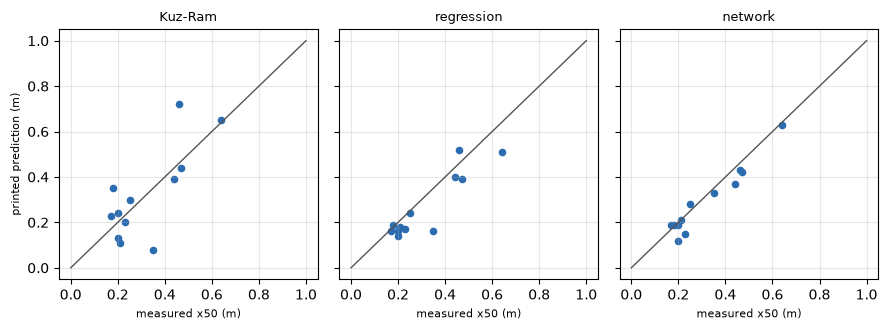

In [6]:
# Printed predictions against measurements for the three published predictors
measured = np.array([b.x50_m for b in holdout])
fig, axes = plt.subplots(1, 3, figsize=(9, 3.4), sharex=True, sharey=True)
for ax, (label, column) in zip(axes, columns.items()):
    values = np.array([b.meta["published"][column] for b in holdout])
    ax.scatter(measured, values, s=20, color="#2b6cb0")
    ax.plot([0, 1], [0, 1], color="#555", lw=1)
    ax.set_title(label.split(" (")[0], fontsize=9)
    ax.set_xlabel("measured x50 (m)", fontsize=8)
    ax.grid(alpha=0.3)
axes[0].set_ylabel("printed prediction (m)", fontsize=8)
fig.tight_layout()
plt.show()

## State of the art

- **Hudaverdi, Kulatilake and Kuzu 2010** (https://doi.org/10.1002/nag.957) fit a regression to the 97 blasts, route each blast to one of two rock-stiffness groups with a discriminant, and validate on a 13-blast hold-out against a Kuz-Ram column.
- **Kulatilake, Hudaverdi and Wu 2012** (https://doi.org/10.1007/s10706-012-9496-3) add a back-propagation network (7 inputs, one hidden layer, Levenberg-Marquardt, one network per group) and validate the three predictors on a 12-blast hold-out. The SDD records that the published parity fit of the Kuz-Ram column on that hold-out is 0.5697.
- **Amoako, Jha and Zhong 2022** (https://doi.org/10.3390/mining2020013) reprint the classical equation and its corrections that the engine's classical arm follows.

Both validations are reported as a table of predictions on a small fixed hold-out, with the correlation as the headline statistic.

## Results

**The same column has two scores, and they tell different stories.** For the printed Kuz-Ram column the Pearson r2 is moderate while the variance explained about the identity line is far lower: the predictions are correlated with the measurements, but they are not close to them. The regression and the network keep a high value on both statistics. A table reported only with the correlation would rank the classical column higher than it deserves.

**Applying the published equations correctly beats the tables the papers printed.** On both hold-outs the recomputed regression has a higher variance explained than the printed column for the same blasts, by about 0.11 and 0.12, and the notebook's numbers equal the values the bake committed. The printed table, not the equation, carries the transcription loss.

**The classical column and the engine's classical arm agree to rounding.** The largest gap is below the rounding of the printed values, which is expected because the rock factors were recovered from this very column (the circularity noted in the previous notebook): this agreement is a consistency check of the geometry, not independent evidence of skill.

**One shared blast moves the picture.** Removing the blast that is also in the training table changes the classical column's variance explained noticeably and the other two columns very little: a fixed hold-out of 12 blasts is sensitive to a single row.

**What this does not show.** All of this is on 12 or 13 blasts from sites that are also in the training table, so none of it says how a predictor behaves at a mine it has not seen. That is the question of topic 04, and level 2 of this topic shows how the classical arm borrows part of its score from knowing the site.

## Summary

- A printed prediction table can be scored like any other prediction, and two statistics that share a name give different answers on the same column.
- The published regression, applied from its equations, beats the table printed for it on both hold-outs; the engine reproduces the committed numbers.
- The classical column and the classical arm agree to rounding because the rock factors were recovered from that column.
- Next: notebook 04 asks how much of the classical score survives when the site is not known in advance (level 4).

## References

- Hudaverdi, Kulatilake and Kuzu 2010, https://doi.org/10.1002/nag.957 (the regression, the discriminant, the 13-blast hold-out)
- Kulatilake, Hudaverdi and Wu 2012, https://doi.org/10.1007/s10706-012-9496-3 (the network and the 12-blast hold-out)
- Amoako, Jha and Zhong 2022, https://doi.org/10.3390/mining2020013 (the classical equation as reprinted)
- `blastfrag` 0.4.0, the engine, on PyPI: https://pypi.org/project/blastfrag/